In [1]:
import scanpy as sc
import pandas as pd
import numpy as np

In [2]:
adata = sc.read_mtx('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/you/you_stageIV_raw.mtx').T

In [3]:
adata

AnnData object with n_obs × n_vars = 11008 × 26705

In [4]:
cellnames = pd.read_csv("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/you/you_stageIV_raw_cellnames.csv")["x"]

In [5]:
cellnames 

0        AAACCCAGTAGACGTG-1_1
1        AAACCCATCACGATCA-1_1
2        AAACGAACATCCAACA-1_1
3        AAACGAAGTGTTGACT-1_1
4        AAACGAAGTTTGGAGG-1_1
                 ...         
11003    TTTGGTTTCTATACGG-1_3
11004    TTTGTTGCAGATCCTA-1_3
11005    TTTGTTGCATTGAGCT-1_3
11006    TTTGTTGTCACGTAGT-1_3
11007    TTTGTTGTCATCACCC-1_3
Name: x, Length: 11008, dtype: object

In [6]:
genenames =  pd.read_csv("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/you/you_stageIV_raw_genenames.csv")["x"]

In [7]:
adata.obs_names = cellnames
adata.var_names = genenames

In [8]:
family_info = pd.read_csv('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/you/stemdata_stageIV_metatable.csv')

In [9]:
family_info = family_info.set_index("Unnamed: 0")
family_info

,Sample,Cell.Barcode,Virus.Barcode,Cluster.Id
Unnamed: 0,,,,
AAACCCAGTAGACGTG-1_1,Stage_IV_Exp3,AAACCCAGTAGACGTG,NaN,NaN
AAACCCATCACGATCA-1_1,Stage_IV_Exp3,AAACCCATCACGATCA,CTGTCTGACAGTGTGTGTGTCTCTCTGTCTCA-1-3,IV-OTX2+VLMCs
AAACGAACATCCAACA-1_1,Stage_IV_Exp3,AAACGAACATCCAACA,GTGACTCAGTGACACACAGAGTGTGTGTGTCA-1-3,IV-OTX2+VLMCs
AAACGAAGTGTTGACT-1_1,Stage_IV_Exp3,AAACGAAGTGTTGACT,CTGTGTCAGTGTCTGTGTGTCACTCTGTGAGTCT-1-3,IV-OTX2+VLMCs
AAACGAAGTTTGGAGG-1_1,Stage_IV_Exp3,AAACGAAGTTTGGAGG,GTGTGAGAGTGTGTGTGTCTCTGTCTGTGTGAGTCTCT-1-3,IV-hGluts
...,...,...,...,...
TTTGGTTTCTATACGG-1_3,Stage_IV_Rep3_Exp3,TTTGGTTTCTATACGG,NaN,NaN
TTTGTTGCAGATCCTA-1_3,Stage_IV_Rep3_Exp3,TTTGTTGCAGATCCTA,NaN,NaN
TTTGTTGCATTGAGCT-1_3,Stage_IV_Rep3_Exp3,TTTGTTGCATTGAGCT,NaN,NaN


In [10]:
adata.obs["barcode"] = adata.obs_names.map(family_info["Virus.Barcode"])

In [11]:
adata.obs["barcode"]

x
AAACCCAGTAGACGTG-1_1                                           NaN
AAACCCATCACGATCA-1_1          CTGTCTGACAGTGTGTGTGTCTCTCTGTCTCA-1-3
AAACGAACATCCAACA-1_1          GTGACTCAGTGACACACAGAGTGTGTGTGTCA-1-3
AAACGAAGTGTTGACT-1_1        CTGTGTCAGTGTCTGTGTGTCACTCTGTGAGTCT-1-3
AAACGAAGTTTGGAGG-1_1    GTGTGAGAGTGTGTGTGTCTCTGTCTGTGTGAGTCTCT-1-3
                                           ...                    
TTTGGTTTCTATACGG-1_3                                           NaN
TTTGTTGCAGATCCTA-1_3                                           NaN
TTTGTTGCATTGAGCT-1_3                                           NaN
TTTGTTGTCACGTAGT-1_3                                           NaN
TTTGTTGTCATCACCC-1_3                                           NaN
Name: barcode, Length: 11008, dtype: object

In [12]:
adata_no_nan = adata[~adata.obs["barcode"].isna()]

In [21]:
import pandas as pd
import numpy as np
from scipy import sparse

# ---------------------------------------------------------
# 1. File and sheet
# ---------------------------------------------------------

excel_path = (
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/raw_datasets/"
    "you/GSE221592_Virusbar_processed_data_combined.xlsx"
)

stage4_sheet = "Clone_stage_IV_Exp#3"


# ---------------------------------------------------------
# 2. Keep only cells with an already assigned virus barcode
#    .copy() avoids the ImplicitModificationWarning
# ---------------------------------------------------------

adata_no_nan = adata[
    adata.obs["barcode"].notna()
].copy()


# ---------------------------------------------------------
# 3. Read the Stage IV annotation sheet
# ---------------------------------------------------------

stage4_metadata = pd.read_excel(
    excel_path,
    sheet_name=stage4_sheet,
    dtype={
        "Cell.Barcode": str,
        "Virus.Barcode": str,
        "Cluster.Id": str,
    }
)

stage4_metadata = stage4_metadata[
    ["Cell.Barcode", "Virus.Barcode", "Cluster.Id"]
].copy()


# ---------------------------------------------------------
# 4. Normalize cell barcodes
#
# Examples:
# AAACCCAGTAGACGTG-1_1 -> AAACCCAGTAGACGTG
# AAACCCAGTAGACGTG-1_3 -> AAACCCAGTAGACGTG
# AAACCCAGTAGACGTG-1   -> AAACCCAGTAGACGTG
# AAACCCAGTAGACGTG     -> AAACCCAGTAGACGTG
# ---------------------------------------------------------

def normalize_cell_barcodes(values):
    return (
        pd.Series(values, dtype="string")
        .str.strip()
        .str.replace(r"_\d+$", "", regex=True)
        .str.replace(r"-1$", "", regex=True)
    )


stage4_metadata["_cell_key"] = normalize_cell_barcodes(
    stage4_metadata["Cell.Barcode"]
).to_numpy()

stage4_metadata["_virus_key"] = (
    stage4_metadata["Virus.Barcode"]
    .astype("string")
    .str.strip()
)


adata_no_nan.obs["_cell_key"] = normalize_cell_barcodes(
    adata_no_nan.obs_names
).to_numpy()

adata_no_nan.obs["_virus_key"] = (
    adata_no_nan.obs["barcode"]
    .astype("string")
    .str.strip()
)


# ---------------------------------------------------------
# 5. Check whether the same cell + virus combination has
#    conflicting cell-type annotations
# ---------------------------------------------------------

annotation_conflicts = (
    stage4_metadata
    .groupby(
        ["_cell_key", "_virus_key"],
        dropna=False
    )["Cluster.Id"]
    .nunique(dropna=False)
)

annotation_conflicts = annotation_conflicts[
    annotation_conflicts > 1
]

if not annotation_conflicts.empty:
    raise ValueError(
        "Some normalized cell-barcode/virus-barcode combinations "
        "have conflicting Cluster.Id annotations."
    )


# Remove harmless duplicate rows, if any
stage4_metadata_unique = (
    stage4_metadata
    .drop_duplicates(
        subset=["_cell_key", "_virus_key"]
    )
    .set_index(["_cell_key", "_virus_key"])
)


# ---------------------------------------------------------
# 6. Map Cluster.Id using both:
#       normalized cell barcode + virus barcode
# ---------------------------------------------------------

adata_matching_index = pd.MultiIndex.from_arrays(
    [
        adata_no_nan.obs["_cell_key"],
        adata_no_nan.obs["_virus_key"],
    ],
    names=["_cell_key", "_virus_key"]
)

adata_no_nan.obs["cell_type"] = (
    stage4_metadata_unique["Cluster.Id"]
    .reindex(adata_matching_index)
    .to_numpy()
)


# ---------------------------------------------------------
# 7. Report matching
# ---------------------------------------------------------

n_matched = adata_no_nan.obs["cell_type"].notna().sum()
n_total = adata_no_nan.n_obs
n_missing = adata_no_nan.obs["cell_type"].isna().sum()

print(f"Stage IV lineage-labelled cells: {n_total}")
print(f"Matched cell types:             {n_matched}")
print(f"Missing cell types:             {n_missing}")
print(f"Matched percentage:             {100 * n_matched / n_total:.2f}%")


print("\nCell-type counts:")
print(
    adata_no_nan.obs["cell_type"]
    .value_counts(dropna=False)
)



Stage IV lineage-labelled cells: 3191
Matched cell types:             3191
Missing cell types:             0
Matched percentage:             100.00%

Cell-type counts:
IV-Seros         721
IV-LUM+VLMCs     566
IV-OTX2+VLMCs    560
IV-hGluts        465
IV-Motors        301
IV-mGluts        170
IV-mDAs          139
IV-Cycling       126
IV-GABAs         114
IV-APOD+VLMCs     29
Name: cell_type, dtype: int64


In [22]:
adata_no_nan

AnnData object with n_obs × n_vars = 3191 × 26705
    obs: 'barcode', '_cell_key', '_virus_key', 'cell_type'

In [23]:
# check MT percentage 

# Mark MT genes
adata_no_nan.var["mt"] = adata_no_nan.var_names.str.upper().str.startswith("MT-")

# Compute MT % per cell
sc.pp.calculate_qc_metrics(adata_no_nan, qc_vars=["mt"], inplace=True)

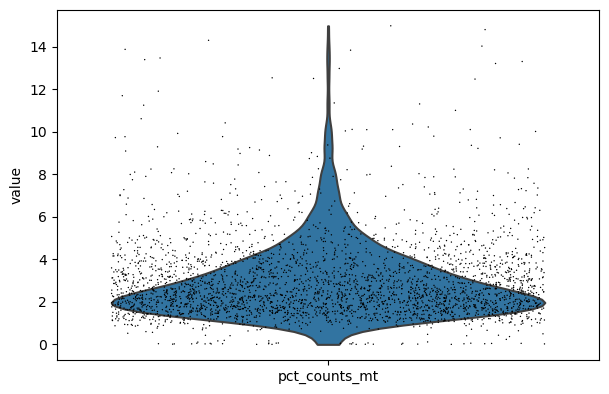

In [24]:
sc.pl.violin(adata_no_nan, 'pct_counts_mt', jitter=0.4)

In [25]:
# Filter cells with >5% MT
adata_no_nan = adata_no_nan[adata_no_nan.obs["pct_counts_mt"] <= 5].copy()

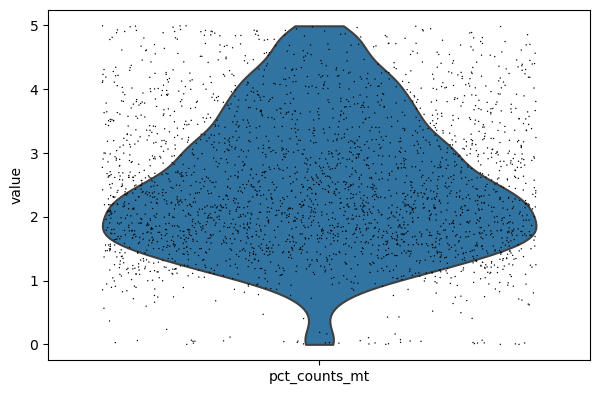

In [26]:
sc.pl.violin(adata_no_nan, 'pct_counts_mt', jitter=0.4)

In [27]:
sc.pp.filter_cells(adata_no_nan, min_genes=100)
sc.pp.filter_genes(adata_no_nan, min_cells=2)

In [28]:
sc.pp.normalize_total(adata_no_nan , target_sum=1e4)
sc.pp.log1p(adata_no_nan)


adata_filtered = adata_no_nan

In [29]:
df = pd.DataFrame(adata_filtered.X.todense(), columns = adata_filtered.var_names)

In [30]:
df["cell_type"] = adata_filtered.obs["cell_type"].to_numpy()

In [31]:
df["barcode"] = adata_filtered.obs["barcode"].values

In [32]:
barcode_df = {}
k = 0
for i in df["barcode"].unique():
    barcode_df[i] = k
    k +=1

In [33]:
df["barcode_cont"] = df["barcode"].map(barcode_df)

In [34]:
df["barcode_cont"].unique().shape == df["barcode"].unique().shape

True

In [35]:
df

x,RP11-34P13.7,FO538757.2,AP006222.2,RP4-669L17.10,RP5-857K21.4,RP11-206L10.9,FAM87B,LINC00115,FAM41C,RP11-54O7.16,...,RP11-558A11.1,MIR2117HG,RP11-756J15.3,LINC01440,FPR3,CECR7,CTA-992D9.6,cell_type,barcode,barcode_cont
0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,IV-OTX2+VLMCs,CTGTCTGACAGTGTGTGTGTCTCTCTGTCTCA-1-3,0
1,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,IV-OTX2+VLMCs,GTGACTCAGTGACACACAGAGTGTGTGTGTCA-1-3,1
2,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,IV-OTX2+VLMCs,CTGTGTCAGTGTCTGTGTGTCACTCTGTGAGTCT-1-3,2
3,0.0,0.000000,0.458030,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,IV-hGluts,GTGTGAGAGTGTGTGTGTCTCTGTCTGTGTGAGTCTCT-1-3,3
4,0.0,0.695254,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,IV-GABAs,GAGTCTGTCTCACTCTGTGACTGTCTGAGTGT-1-3,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2859,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,IV-GABAs,GTCTGTGACTCTCTGTCTGTCTGTCACTGTGT-2-3,2000
2860,0.0,0.000000,1.317476,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,IV-Seros,GTCTCTGTGTCTGTGTCAGTCAGTGTCTGTCT-2-3,2001
2861,0.0,0.319363,0.319363,0.0,0.0,0.0,0.0,0.0,0.0,0.319363,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,IV-Motors,GTCTCTCAGAGTCTCAGTCTGTGTGTCAGACT-2-3,2002
2862,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,IV-hGluts,GTGTGAGTGTGTGTGTGTGACTCTGTGTGTGT-2-3,1184


In [36]:
df = df.drop("barcode", axis=1)

In [37]:
df.to_pickle('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered_with_celltype/you_stage4_barcode_all_genes.pkl')
